# 8. Auditoria de rótulos

← [Modelo final e análises](07_final_model.ipynb) · [índice](README.pt-BR.md) · [Predições do conjunto sem rótulo](09_unlabeled_set_predictions.ipynb) →

Vários erros do modelo final com 100% de confiança parecem ser erros **do rótulo**, não do modelo
(por exemplo, um 3 nítido rotulado como 1). Aqui eu meço quantos rótulos do SVHN são suspeitos.

**Método** (inspirado em *confident learning*):
- uso só imagens que **nenhum modelo viu no treino**: validação (7.326) e teste (26.032);
- passo essas imagens pelos **14 checkpoints de CNN** do estudo (E4 a E17), treinados de forma independente;
- uma imagem é **suspeita** quando a classe da média dos 14 modelos é diferente do rótulo, pelo menos 13 dos 14
  modelos votam nessa classe e a probabilidade média do rótulo é menor que 5%.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from svhn_utils import figures_dir, get_device, load_data, load_model, predict_proba
FIG_DIR = figures_dir("08_label_noise_audit")   # figuras deste notebook em outputs/figures/08_label_noise_audit/

device = get_device()
data, split = load_data()
sets = {"val": (*data["val"], split["val"]), "test": (*data["test"], torch.arange(len(data["test"][1])))}

probs = {k: [] for k in sets}
for i in range(4, 18):                       # checkpoints baixados do Hugging Face se necessário
    model, norm, _ = load_model(f"E{i}", device)
    for k, (X, y, _) in sets.items():
        probs[k].append(predict_proba(model, X.to(device), norm))

In [2]:
rows = []
for k, (X, y, file_idx) in sets.items():
    P = torch.stack(probs[k])                     # [14 modelos, N, 10]
    mean, votes = P.mean(0), P.argmax(2)
    ens = mean.argmax(1)
    agree = (votes == ens).sum(0)
    p_label = mean[torch.arange(len(y)), y]
    sus = (ens != y) & (agree >= 13) & (p_label < 0.05)
    print(f"{k:4s}: {len(y):,} imagens | acurácia do ensemble {(ens == y).float().mean()*100:.2f}% | "
          f"suspeitas {int(sus.sum())} ({sus.float().mean()*100:.2f}%)")
    for n in sus.nonzero().squeeze(1).tolist():
        rows.append(dict(split=k, i=n, arquivo=("test" if k == "test" else "train") + "_32x32.mat",
                         indice_no_arquivo=int(file_idx[n]), rotulo=int(y[n]), ensemble=int(ens[n]),
                         votos=int(agree[n]), p_rotulo=float(p_label[n])))
sus_df = pd.DataFrame(rows).sort_values("p_rotulo").reset_index(drop=True)
print("pares (rótulo → ensemble) mais comuns:", Counter(zip(sus_df.rotulo, sus_df.ensemble)).most_common(8))
sus_df.head(10)

val : 7,326 imagens | acurácia do ensemble 96.06% | suspeitas 52 (0.71%)
test: 26,032 imagens | acurácia do ensemble 97.15% | suspeitas 136 (0.52%)
pares (rótulo → ensemble) mais comuns: [((2, 1), 9), ((1, 3), 8), ((5, 1), 7), ((1, 2), 7), ((7, 1), 7), ((3, 1), 7), ((4, 1), 7), ((3, 9), 6)]


,split,i,arquivo,indice_no_arquivo,rotulo,ensemble,votos,p_rotulo
0,test,15700,test_32x32.mat,15700,3,0,14,2.094563e-09
1,test,20757,test_32x32.mat,20757,8,4,14,6.636261e-09
2,test,15843,test_32x32.mat,15843,3,9,14,8.521946e-09
3,test,3917,test_32x32.mat,3917,3,6,14,2.750508e-08
4,test,8239,test_32x32.mat,8239,0,5,14,9.438850e-08
5,test,3251,test_32x32.mat,3251,5,9,14,1.816501e-07
6,test,1318,test_32x32.mat,1318,5,0,14,1.925750e-07
7,test,6492,test_32x32.mat,6492,1,3,14,2.766569e-07
8,test,8252,test_32x32.mat,8252,5,8,14,4.177651e-07
9,test,17017,test_32x32.mat,17017,7,4,14,6.417923e-07


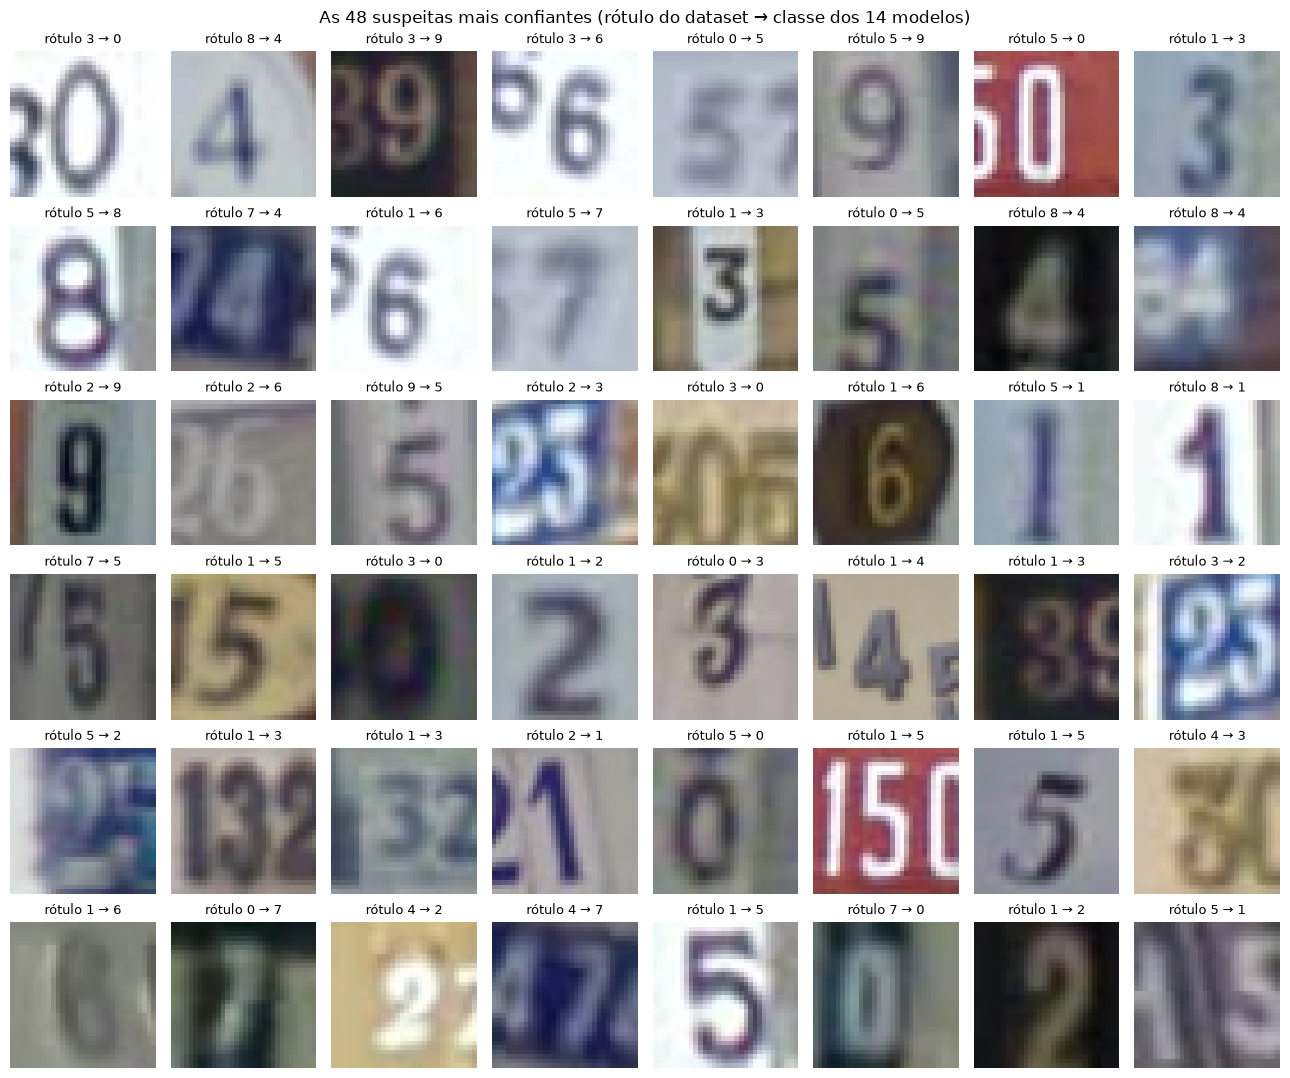

In [3]:
top = sus_df.head(48)
fig, axes = plt.subplots(6, 8, figsize=(13, 11))
for ax, (n, r) in zip(axes.flat, top.iterrows()):
    ax.imshow(sets[r.split][0][r.i].permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"rótulo {r.rotulo} → {r.ensemble}", fontsize=9)
plt.suptitle("As 48 suspeitas mais confiantes (rótulo do dataset → classe dos 14 modelos)")
plt.tight_layout(); plt.savefig(FIG_DIR / "label_noise_suspects.png", dpi=150); plt.show()

## Verificação no arquivo original

Para descartar um erro de carregamento (imagem trocada ou rótulo deslocado), leio as primeiras suspeitas
direto dos arquivos `.mat` oficiais, sem passar pelo `torchvision`. No arquivo, o dígito 0 é guardado como 10.

In [4]:
import scipy.io as sio

from svhn_utils import DATA_DIR

mats = {f: sio.loadmat(DATA_DIR / f) for f in sus_df.arquivo.unique()}
for _, r in sus_df.head(8).iterrows():
    m = mats[r.arquivo]
    img, lab = m["X"][:, :, :, r.indice_no_arquivo], int(m["y"][r.indice_no_arquivo, 0])
    same = np.array_equal(img, sets[r.split][0][r.i].permute(1, 2, 0).numpy())
    print(f"{r.arquivo}[{r.indice_no_arquivo}]: rótulo no arquivo {lab} ({lab % 10}) | pixels idênticos: {same} "
          f"| 14 modelos: {r.ensemble}")

test_32x32.mat[15700]: rótulo no arquivo 3 (3) | pixels idênticos: True | 14 modelos: 0
test_32x32.mat[20757]: rótulo no arquivo 8 (8) | pixels idênticos: True | 14 modelos: 4
test_32x32.mat[15843]: rótulo no arquivo 3 (3) | pixels idênticos: True | 14 modelos: 9
test_32x32.mat[3917]: rótulo no arquivo 3 (3) | pixels idênticos: True | 14 modelos: 6
test_32x32.mat[8239]: rótulo no arquivo 10 (0) | pixels idênticos: True | 14 modelos: 5
test_32x32.mat[3251]: rótulo no arquivo 5 (5) | pixels idênticos: True | 14 modelos: 9
test_32x32.mat[1318]: rótulo no arquivo 5 (5) | pixels idênticos: True | 14 modelos: 0
test_32x32.mat[6492]: rótulo no arquivo 1 (1) | pixels idênticos: True | 14 modelos: 3


## Efeito no modelo final

Se as suspeitas forem de fato rótulos errados, parte dos erros do modelo final no teste são acertos contra um
rótulo errado. Abaixo, a acurácia do E16 com e sem as imagens suspeitas.

In [5]:
model, norm, _ = load_model("best_model", device)
Xte, yte = data["test"]
pred = predict_proba(model, Xte.to(device), norm).argmax(1)
mask = torch.ones(len(yte), dtype=torch.bool)
t = sus_df[sus_df.split == "test"]
mask[torch.tensor(t.i.values)] = False
agrees = (pred[torch.tensor(t.i.values)] == torch.tensor(t.ensemble.values)).sum().item()
print(f"acurácia no teste completo:          {(pred == yte).float().mean()*100:.2f}% ({len(yte):,} imagens)")
print(f"acurácia sem as {len(t)} suspeitas:      {(pred[mask] == yte[mask]).float().mean()*100:.2f}% ({mask.sum().item():,} imagens)")
print(f"suspeitas em que o E16 concorda com o ensemble (e conta como erro): {agrees} de {len(t)}")

acurácia no teste completo:          97.13% (26,032 imagens)
acurácia sem as 136 suspeitas:      97.64% (25,896 imagens)
suspeitas em que o E16 concorda com o ensemble (e conta como erro): 133 de 136


## Conclusão

Inspecionando as suspeitas, elas se dividem em quatro tipos:

1. **Rótulo claramente errado:** o dígito está nítido e o rótulo é outro (por exemplo, um 4 rotulado como 8).
   São a maioria entre as suspeitas mais confiantes.
2. **Ambiguidade de recorte:** há vários dígitos e o rótulo se refere a um vizinho, não ao central (por
   exemplo, "150" rotulado como 1).
3. **Ilegíveis:** borradas ou escuras demais para saber o dígito; aqui os modelos estão apenas chutando.
4. **Sem dígito:** recortes sem número ou com uma letra.

Portanto, o SVHN tem ruído de rótulo: cerca de 0,5% do teste e 0,7% da validação são suspeitos, e parte dos
erros "confiantes" do modelo final são, na verdade, erros do dataset. Isso deixa a acurácia de 97,13% um pouco
pessimista. Pelo mesmo motivo do notebook [2](02_data_quality.ipynb), os rótulos não foram corrigidos: os
resultados continuam medidos nos splits oficiais.